In [3]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

In [5]:
Walmart_sales = pd.read_csv('Walmart_Sales.csv')
Walmart_sales.head(20)

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
5,1,12-03-2010,1439541.59,0,57.79,2.667,211.380643,8.106
6,1,19-03-2010,1472515.79,0,54.58,2.720,211.215635,8.106
7,1,26-03-2010,1404429.92,0,51.45,2.732,211.018042,8.106
8,1,02-04-2010,1594968.28,0,62.27,2.719,210.820450,7.808
9,1,09-04-2010,1545418.53,0,65.86,2.770,210.622857,7.808


In [9]:
Walmart_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 465.2 KB


In [7]:
Walmart_sales.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [8]:
Walmart_sales.dtypes

Store             int64
Date                str
Weekly_Sales    float64
Holiday_Flag      int64
Temperature     float64
Fuel_Price      float64
CPI             float64
Unemployment    float64
dtype: object

In [13]:
Walmart_sales['Date'] = pd.to_datetime(Walmart_sales['Date'], format ='%d-%m-%Y')
Walmart_sales['Year'] = Walmart_sales['Date'].dt.year

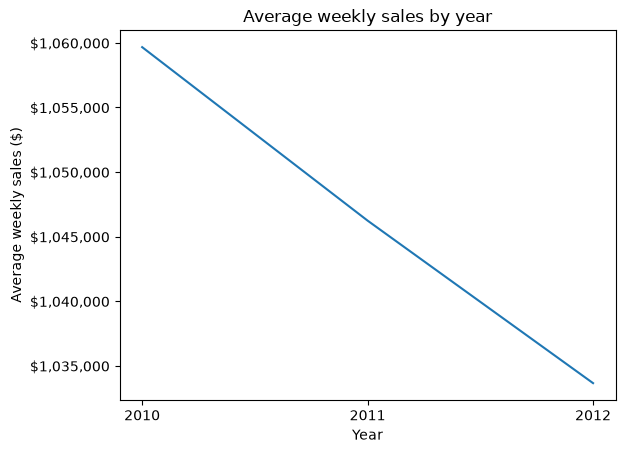

In [23]:
yearly_sales = Walmart_sales.groupby('Year', as_index=False)['Weekly_Sales'].mean()
ax = sns.lineplot(data=yearly_sales, x="Year", y="Weekly_Sales")



ax.yaxis.set_major_formatter("${x:,.0f}")


ax.set_xticks([2010, 2011, 2012])

plt.title("Average weekly sales by year")
plt.xlabel("Year")
plt.ylabel("Average weekly sales ($)")
plt.show()

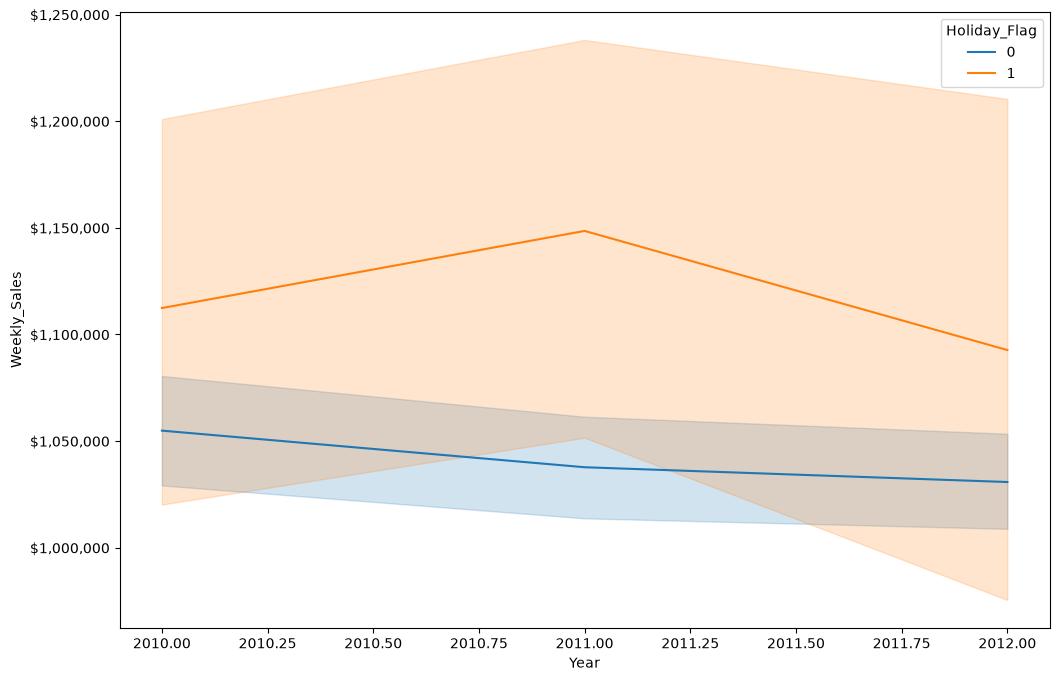

In [ ]:
plt.figure(figsize=(12,8))
ax = sns.lineplot(data=Walmart_sales, x="Year", y="Weekly_Sales", hue ='Holiday_Flag')
ax.yaxis.set_major_formatter("${x:,.0f}")


In [27]:
cols = ["CPI", "Unemployment", "Temperature"]
results = pd.DataFrame({
    "Pearson": [Walmart_sales["Weekly_Sales"].corr(Walmart_sales[c]) for c in cols],
    "Spearman": [Walmart_sales["Weekly_Sales"].corr(Walmart_sales[c], method="spearman") for c in cols],
}, index=cols).round(3)
print(results)

              Pearson  Spearman
CPI            -0.073    -0.055
Unemployment   -0.106    -0.062
Temperature    -0.064    -0.071


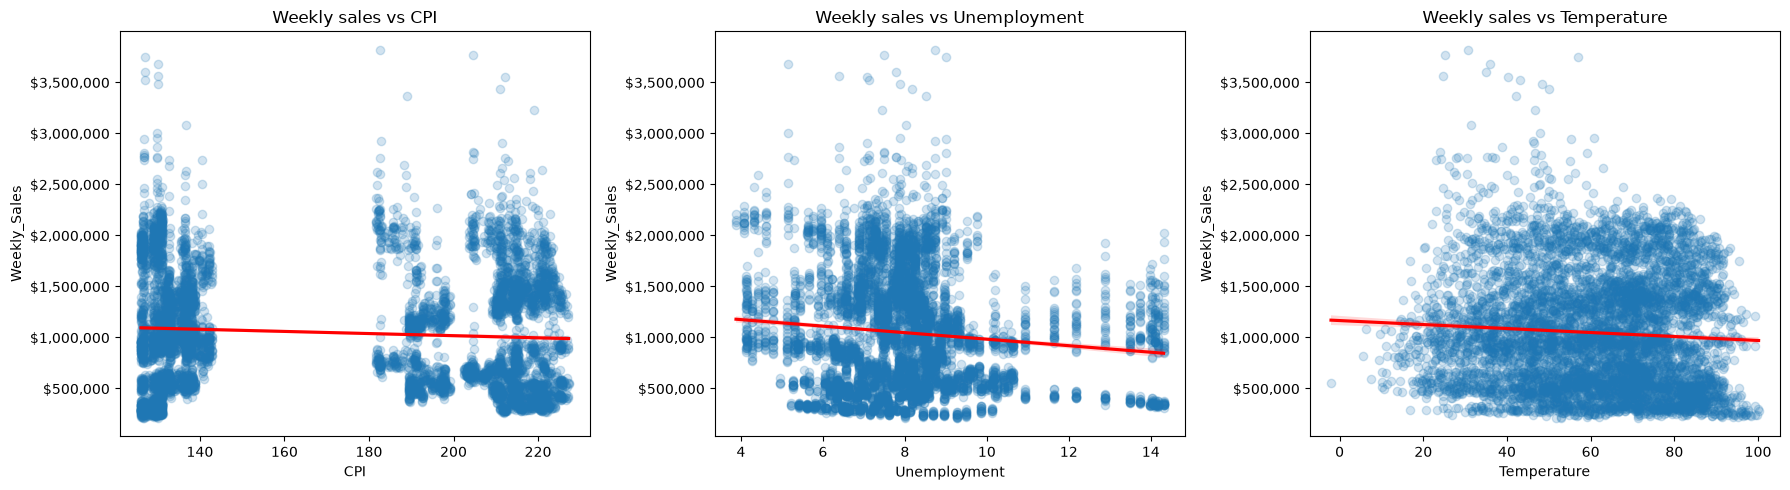

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["CPI", "Unemployment", "Temperature"]):
    sns.regplot(data=Walmart_sales, x=col, y="Weekly_Sales", ax=ax,
                scatter_kws={"alpha": 0.2}, line_kws={"color": "red"})
    ax.set_title(f"Weekly sales vs {col}")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.show()

In [29]:
Walmart_sales["Month"] = Walmart_sales["Date"].dt.month
like_for_like = Walmart_sales[Walmart_sales["Month"].between(2, 10)]
print(like_for_like.groupby("Year")["Weekly_Sales"].mean().round(0))

Year
2010    1024087.0
2011    1017809.0
2012    1043441.0
Name: Weekly_Sales, dtype: float64


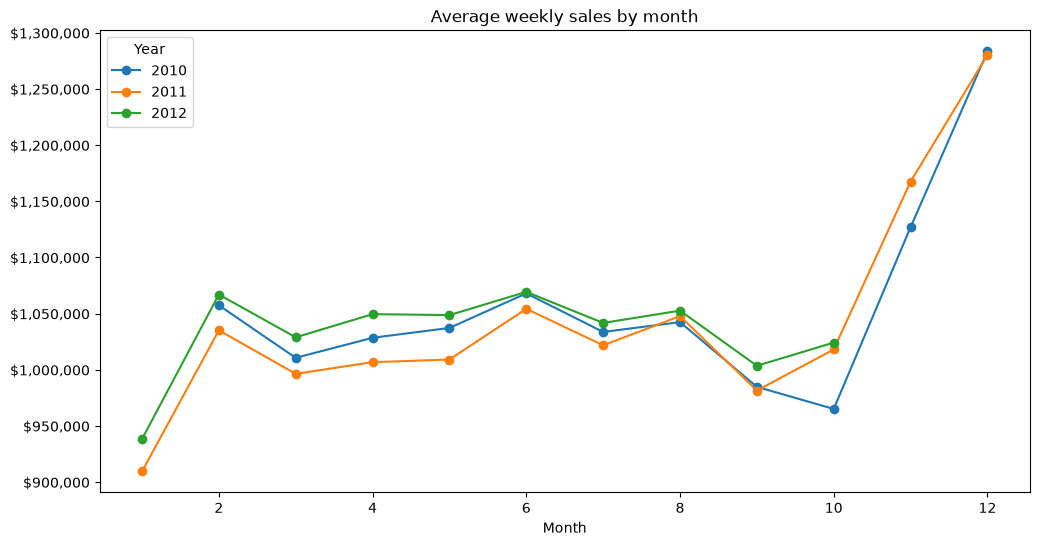

In [30]:
monthly = Walmart_sales.pivot_table(index="Month", columns="Year",
                                    values="Weekly_Sales", aggfunc="mean")
ax = monthly.plot(figsize=(12, 6), marker="o")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.title("Average weekly sales by month")
plt.show()

In [31]:
holiday_names = {2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas"}
hol = Walmart_sales[Walmart_sales["Holiday_Flag"] == 1].copy()
hol["Holiday"] = hol["Month"].map(holiday_names)
normal_avg = Walmart_sales.loc[Walmart_sales["Holiday_Flag"] == 0, "Weekly_Sales"].mean()

print(hol.groupby("Holiday")["Weekly_Sales"].mean().round(0))
print("Non-holiday average:", round(normal_avg))

Holiday
Christmas        960833.0
Labor Day       1042427.0
Super Bowl      1079128.0
Thanksgiving    1471273.0
Name: Weekly_Sales, dtype: float64
Non-holiday average: 1041256


             mean        std  variability
Store                                    
20     2107676.87  275900.56         0.13
4      2094712.96  266201.44         0.13
14     2020978.40  317569.95         0.16
13     2003620.31  265507.00         0.13
2      1925751.34  237683.69         0.12
10     1899424.57  302262.06         0.16
27     1775216.20  239930.14         0.14
6      1564728.19  212525.86         0.14
1      1555264.40  155980.77         0.10
39     1450668.13  217466.45         0.15


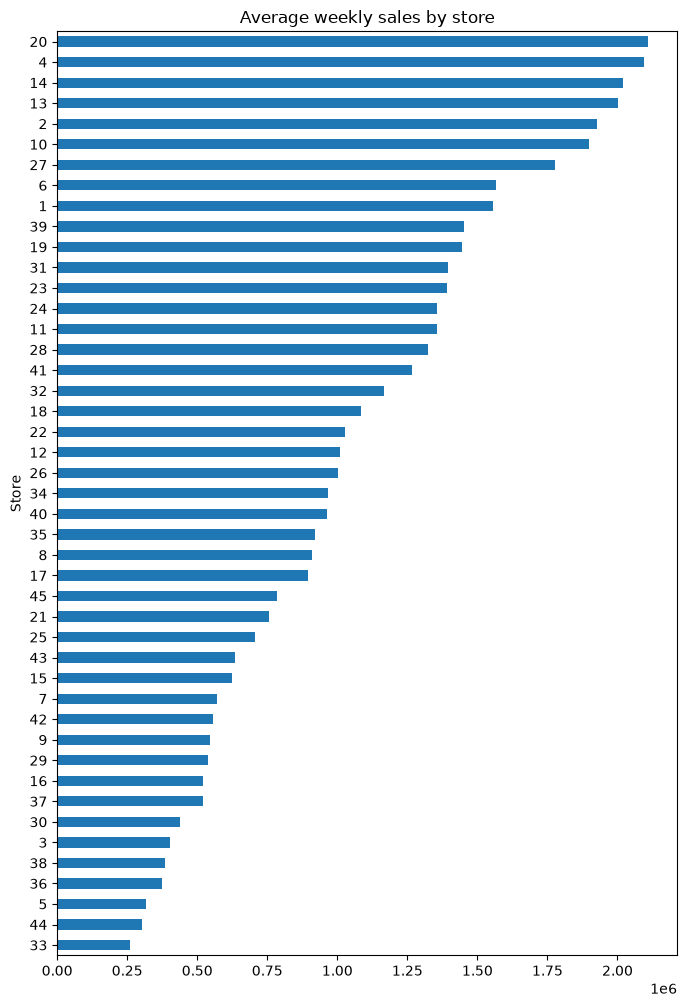

In [32]:
store_stats = Walmart_sales.groupby("Store")["Weekly_Sales"].agg(["mean", "std"])
store_stats["variability"] = store_stats["std"] / store_stats["mean"]
print(store_stats.sort_values("mean", ascending=False).head(10).round(2))

store_stats["mean"].sort_values().plot(kind="barh", figsize=(8, 12))
plt.title("Average weekly sales by store")
plt.show()

In [33]:
Walmart_sales["Sales_index"] = (Walmart_sales["Weekly_Sales"] /
    Walmart_sales.groupby("Store")["Weekly_Sales"].transform("mean"))

for col in ["CPI", "Unemployment", "Temperature", "Fuel_Price"]:
    print(col, round(Walmart_sales["Sales_index"].corr(Walmart_sales[col]), 3))

CPI 0.002
Unemployment -0.018
Temperature -0.079
Fuel_Price -0.033


In [ ]:
# ===================== SUMMARY OF RESULTS =====================
# Data: Walmart weekly sales, 6,435 rows x 8 columns (45 stores x 143
# weeks, Feb 2010 to Oct 2012). No missing values.
#
# Methods: parsed dates and derived Year and Month; compared yearly sales
# (all months, then Feb-Oct only); analysed monthly seasonality, holiday
# weeks and store averages; correlated sales with CPI, unemployment,
# temperature and fuel price, before and after removing the store effect.
#
# Findings:
# 1. Raw correlations with weekly sales are all weak (Pearson):
#    CPI -0.073, Unemployment -0.106, Temperature -0.064.
# 2. Store differences are the main driver: average weekly sales range
#    from about $2.11M (Store 20) to about $260K (Store 33), roughly 8x.
#    After dividing each store's sales by its own average, correlations
#    fall to ~0: CPI 0.002, Unemployment -0.018, Fuel price -0.033
#    (Temperature stays at -0.079, a seasonal proxy).
# 3. Strong seasonality: sales jump in Nov-Dec (December about $1.28M
#    per week vs ~$1.0-1.07M in most months) in all three years.
# 4. Holiday effect varies. Vs a non-holiday average of $1.04M:
#    Thanksgiving $1.47M (+41%), Super Bowl +4%, Labor Day ~0%,
#    Christmas flagged weeks -8% (the flag likely falls after the rush).
# 5. No real decline: Feb-Oct averages are $1.024M (2010), $1.018M
#    (2011), $1.043M (2012). The apparent drop came from 2012 having
#    no Nov/Dec weeks.
#
# Limitations: short period; no store size or location data; CPI and
# unemployment are regional; temperature assumed Fahrenheit; correlation
# does not show causation.
# ==============================================================